In [ ]:
# CELL 1: Install & Upgrade Packages + Auto-Restart Kernel for Python 3.13
!pip install -q -U "bitsandbytes>=0.46.1" "transformers>=4.46.0" "accelerate>=0.34.0" "peft>=0.13.0" "datasets" "trl" "scipy" "matplotlib"

import os
print("✅ Packages upgraded! Restarting Python kernel automatically so bitsandbytes loads cleanly...")
os._exit(0)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gtts 2.5.4 requires click<8.2,>=7.1, but you have click 8.5.1 which is incompatible.


In [ ]:
# CELL 2: Generate SevaSetu Palghar Training Dataset (.jsonl)
import json

base_qa_pairs = [
    {
        "instruction": "You areSevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "मी जव्हार तालुक्यातील आदिवासी शेतकरी आहे. मला कच्चे घर पक्के बांधण्यासाठी कोणती सरकारी योजना मिळेल आणि काय कागदपत्रे लागतील?",
        "output": "### १. संबंधित सरकारी योजना (Scheme Name):\n**शबरी आदिवासी घरकुल योजना (Shabari Adivasi Gharkul Yojana)** - एकात्मिक आदिवासी विकास प्रकल्प (ITDP), जव्हार/डहाणू, जिल्हा पालघर.\n\n### २. पात्रता निकष (Eligibility):\n* अर्जदार पालघर जिल्ह्यातील अनुसूचित जमातीचा (Scheduled Tribe - ST) असावा.\n* अर्जदाराचे स्वतःचे पक्के घर नसावे (कच्चे घर किंवा बेघर असावा).\n* वार्षिक कौटुंबिक उत्पन्न मर्यादा ₹१,२०,००० पेक्षा कमी असावी.\n\n### ३. आवश्यक कागदपत्रांची यादी (Document Checklist):\n* [ ] जातीचा दाखला (ST Caste Certificate - प्रांत अधिकारी जव्हार/डहाणू कडील)\n* [ ] ७/१२ उतारा किंवा गाव नमुना ८अ (जागेचा पुरावा)\n* [ ] तहसीलदार यांचा उत्पन्नाचा दाखला\n* [ ] ग्रामसभेचा ठराव (Gram Sabha Resolution)\n* [ ] आधार कार्ड आणि बँक पासबुक प्रत (DBT साठी)\n* [ ] रेशन कार्ड आणि सद्यस्थितीतील कच्च्या घराचा फोटो\n\n### ४. अर्ज करण्याची पद्धत (How to Apply in Palghar):\nआपल्या गावातील **ग्रामसेवक (Gram Panchayat)** किंवा **गट विकास अधिकारी (BDO), पंचायत समिती जव्हार** येथे कागदपत्रांसह अर्ज सादर करावा."
    },
    {
        "instruction": "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "I am a tribal farmer from Vikramgad taluka in Palghar. I have 2 acres of land and need financial help to dig an irrigation well and buy an electric pump.",
        "output": "### 1. Relevant Government Scheme:\n**Birsa Munda Krushi Kranti Yojana (बिरसा मुंडा कृषी क्रांती योजना)** – Implemented via Zilla Parishad Palghar (Agriculture Department).\n\n### 2. Eligibility Criteria:\n* Must belong to the Scheduled Tribe (ST) category in Palghar district (Vikramgad/Jawhar/Mokhada/Dahanu/Wada/Talasari).\n* Annual family income must be below ₹1,50,000.\n* Landholding must be between 0.40 hectare to 6 hectares (supported by a valid 7/12 extract).\n\n### 3. Subsidy & Benefits:\n* **New Well (नवीन विहीर):** Up to ₹2,50,000 subsidy.\n* **Electric/Solar Pump Set:** Up to ₹20,000 – ₹50,000 subsidy.\n* **PVC Pipes & Drip/Sprinkler Irrigation:** Up to ₹50,000 support.\n\n### 4. Required Document Checklist:\n* [ ] 7/12 Utara and 8-A Extract (सातबारा व ८अ उतारा)\n* [ ] ST Caste Certificate\n* [ ] Income Certificate from Vikramgad Tehsildar\n* [ ] Groundwater Survey (GSDA) feasibility certificate\n* [ ] Aadhaar Card linked to Bank Passbook\n\n### 5. Application Procedure:\nApply online via the **MahaDBT Farmer Portal (`mahadbt.maharashtra.gov.in`)** at your nearest **Setu Kendra / CSC Center in Vikramgad**, and submit the receipt to the **Taluka Krushi Adhikari (Vikramgad)**."
    },
    {
        "instruction": "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "डहाणू आणि सातपाटी मधील मच्छीमारांना बोटीच्या डिझेल अनुदानासाठी आणि बर्फाच्या पेटीसाठी (Ice Box) कोणती योजना आहे?",
        "output": "### १. संबंधित सरकारी योजना (Scheme Name):\n**प्रधानमंत्री मत्स्य संपदा योजना (PMMSY) व महाराष्ट्र शासन डिझेल परतावा योजना** (सहाय्यक आयुक्त मत्स्यव्यवसाय, पालघर).\n\n### २. पात्रता निकष (Eligibility):\n* अर्जदार पालघर जिल्ह्यातील (डहाणू, सातपाटी, अर्नाळा, वसई, केळवे) क्रियाशील मच्छीमार असावा.\n* मच्छीमार सहकारी संस्थेचा सभासद असावा व नौका नोंदणीकृत असावी.\n\n### ३. आवश्यक कागदपत्रांची यादी (Document Checklist):\n* [ ] नौका नोंदणी प्रमाणपत्र (Boat Registration Certificate)\n* [ ] मासेमारी परवाना (Fishing License)\n* [ ] मच्छीमार सहकारी संस्थेचे शिफारस पत्र\n* [ ] आधार कार्ड व राष्ट्रीयकृत बँक पासबुक\n* [ ] डिझेल खरेदीच्या अधिकृत पावत्या\n\n### ४. अर्ज करण्याची पद्धत (How to Apply in Palghar):\nआपल्या गावातील **मच्छीमार सहकारी संस्थेमार्फत** किंवा थेट **सहाय्यक आयुक्त मत्स्यव्यवसाय कार्यालय, पालघर** येथे अर्ज सादर करावा."
    },
    {
        "instruction": "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "I am an engineering student living in Palghar and belong to the ST/OBC category. How do I get tuition fee and hostel scholarship?",
        "output": "### 1. Relevant Government Scheme:\n**Post-Matric Scholarship & Pandit Deendayal Upadhyay Swayam Yojana (पंडित दीनदयाळ उपाध्याय स्वयंम योजना)** – ITDP Dahanu/Jawhar & Social Welfare Dept Palghar.\n\n### 2. Eligibility Criteria:\n* Resident of Maharashtra (Palghar District) belonging to ST / OBC / SC / EBC category.\n* Admitted to a recognized Engineering or Polytechnic college through CAP round.\n* Family annual income below ₹2,50,000 (100% fee waiver) or up to ₹8,00,000 (50% benefit).\n* Under **Swayam Yojana**, ST students receive up to **₹51,000 – ₹60,000/year** directly for food and accommodation.\n\n### 3. Required Document Checklist:\n* [ ] Caste Certificate & Caste Validity Certificate\n* [ ] Tehsildar Income Certificate\n* [ ] CAP Allotment Letter & College Bonafide Certificate\n* [ ] College Fee Receipt & Previous Marksheets\n* [ ] Domicile Certificate & Aadhaar-seeded Bank Account\n\n### 4. Application Procedure:\nApply online at **`mahadbt.maharashtra.gov.in`** and submit the printed form to your college scholarship desk."
    },
    {
        "instruction": "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "मोखाडा किंवा वाडा तालुक्यात वनहक्क कायद्यांतर्गत (Forest Rights Act - कसत असलेल्या वनजमिनीचा सातबारा) दावा कसा करावा?",
        "output": "### १. संबंधित कायदा व योजना (Scheme Name):\n**अनुसूचित जमाती व इतर पारंपरिक वननिवासी (वनहक्कांची मान्यता) अधिनियम २००६ (Forest Rights Act - FRA / वनहक्क पट्टा)** - जिल्हाधिकारी कार्यालय, पालघर.\n\n### २. पात्रता निकष (Eligibility):\n* अर्जदार अनुसूचित जमातीचा (ST) असल्यास १३ डिसेंबर २००५ पूर्वीपासून वनजमीन प्रत्यक्ष कसत असावा (कमाल ४ हेक्टरपर्यंत).\n\n### ३. आवश्यक कागदपत्रांची यादी (Document Checklist):\n* [ ] नमुना 'अ' (Form-A) मधील अर्ज व जातीचा दाखला (ST Certificate)\n* [ ] २००५ पूर्वीचा पुरावा (अतिक्रमण पावती, दंड पावती, जुनी वंशावळ किंवा मतदार यादी)\n* [ ] शेजारील दोन वयोवृद्ध शेतकऱ्यांचे जबाब\n* [ ] वनहक्क समिती व तलाठी/वनरक्षक यांनी केलेला संयुक्त GPS नकाशा\n\n### ४. अर्ज करण्याची पद्धत (How to Apply in Palghar):\nगावातील **ग्रामस्तरीय वनहक्क समिती (FRC)** कडे अर्ज द्यावा. ग्रामसभेच्या मंजुरीनंतर प्रस्ताव **उपविभागीय समिती (SDO जव्हार/वाडा/डहाणू)** व **जिल्हाधिकारी कार्यालय, पालघर** कडे मंजुरीसाठी जातो."
    },
    {
        "instruction": "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        "input": "I am a pregnant woman from a rural village in Mokhada taluka. Which nutrition and cash maternity benefit schemes are available at the Anganwadi and PHC?",
        "output": "### 1. Relevant Government Schemes:\n1. **Dr. APJ Abdul Kalam Amrut Aahar Yojana (डॉ. ए.पी.जे. अब्दुल कलाम अमृत आहार योजना)** – Tribal areas in Palghar.\n2. **Pradhan Mantri Matru Vandana Yojana (PMMVY)**.\n\n### 2. Eligibility & Benefits:\n* **Amrut Aahar Yojana:** Pregnant women and lactating mothers in tribal Palghar (Mokhada, Jawhar, Vikramgad, Talasari, Dahanu, Wada) receive **one full hot nutritious meal daily** free at the local Anganwadi.\n* **PMMVY Cash Benefit:** ₹5,000 in bank installments for the first child.\n\n### 3. Required Document Checklist:\n* [ ] MCP Card (from Anganwadi/ASHA worker)\n* [ ] Aadhaar Card of Mother and Husband\n* [ ] Aadhaar-linked Bank / Post Office Passbook\n\n### 4. Application Procedure:\nRegister with your village **Anganwadi Sevika** or **ASHA Tai** in Mokhada, or visit the nearest **Primary Health Center (PHC)**."
    }
]

expanded_dataset = []
for i in range(20):
    for item in base_qa_pairs:
        expanded_dataset.append(item.copy())

with open("sevasetu_palghar_train.jsonl", "w", encoding="utf-8") as f:
    for entry in expanded_dataset:
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

print(f"✅ Created 'sevasetu_palghar_train.jsonl' with {len(expanded_dataset)} training rows!")

In [2]:
# CELL 3: Load 4-bit Llama-3.1-8B Model & Attach QLoRA Adapters
import os, gc
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import bitsandbytes as bnb
print(f"✅ Active bitsandbytes version: {bnb.__version__}")

from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

for var_name in ["model", "trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()

model_id = "unsloth/Meta-Llama-3.1-8B-Instruct-bnb-4bit"

print("⏳ Downloading & loading 4-bit Llama-3.1-8B model...")
tokenizer = AutoTokenizer.from_pretrained(model_id)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    device_map={"": 0},
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.0,
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
print("✅ Base Model & QLoRA Adapters Loaded Successfully!")

✅ Active bitsandbytes version: 0.50.2
⏳ Downloading & loading 4-bit Llama-3.1-8B model...


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.5k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


trainable params: 41,943,040 || all params: 8,072,204,288 || trainable%: 0.5196
✅ Base Model & QLoRA Adapters Loaded Successfully!


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


In [3]:
# CELL 4: Format & Tokenize Dataset
from datasets import load_dataset

sevasetu_prompt = """Below is an instruction that describes a task, paired with an input from a citizen of Palghar district. Write a structured response that appropriately completes the request.

### Instruction:
{}

### Citizen Query:
{}

### SevaSetu Palghar Response:
{}"""

def format_and_tokenize(batch):
    texts = []
    for inst, inp, out in zip(batch["instruction"], batch["input"], batch["output"]):
        full_text = sevasetu_prompt.format(inst, inp, out) + tokenizer.eos_token
        texts.append(full_text)
    return tokenizer(texts, truncation=True, max_length=512, padding=False)

raw_dataset = load_dataset("json", data_files="sevasetu_palghar_train.jsonl", split="train")
tokenized_dataset = raw_dataset.map(
    format_and_tokenize,
    batched=True,
    remove_columns=raw_dataset.column_names,
)

print(f"✅ Tokenized {len(tokenized_dataset)} training rows successfully!")

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

✅ Tokenized 120 training rows successfully!


In [4]:
# CELL 5: Run QLoRA Fine-Tuning Using Official Hugging Face Trainer
from transformers import Trainer, TrainingArguments, DataCollatorForLanguageModeling

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

training_args = TrainingArguments(
    output_dir="outputs",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    warmup_steps=5,
    max_steps=60,
    learning_rate=2e-4,
    fp16=True,
    logging_steps=5,
    optim="paged_adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="linear",
    seed=3407,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)

print("🚀 Starting QLoRA Fine-Tuning...")
trainer_stats = trainer.train()
print("🎉 TRAINING COMPLETE! Your SevaSetu Palghar LLM is now trained!")

🚀 Starting QLoRA Fine-Tuning...


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss
5,1.926578
10,1.277867
15,0.558920
20,0.153002
25,0.048862
30,0.033903
35,0.028127
40,0.022511
45,0.018365
50,0.016779


🎉 TRAINING COMPLETE! Your SevaSetu Palghar LLM is now trained!


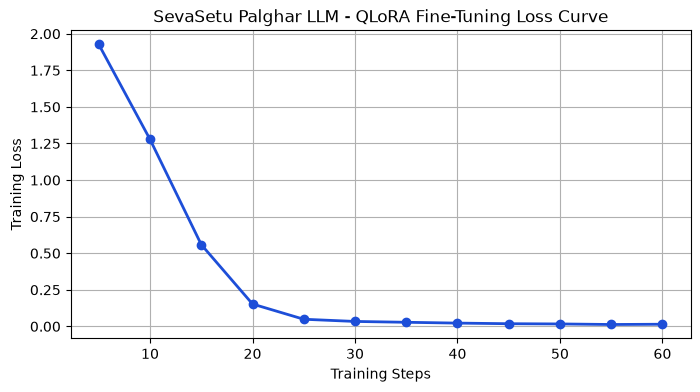


================ SEVASETU MODEL OUTPUT ================

### १. संबंधित सरकारी योजना (Scheme Name):
**शबरी आदिवासी घरकुल योजना (Shabari Adivasi Gharkul Yojana)** - एकात्मिक आदिवासी विकास प्रकल्प (ITDP), विक्रमगड, पालघर.

### २. पात्रता निकष (Eligibility):
* अर्जदार पालघर जिल्ह्यातील अनुसूचित जमातीचा (Scheduled Tribe - ST) असावा.
* अर्जदाराचे स्वतःचे पक्के घर नसावे (दंडक किंवा शेजारील गावातील अन्य शेतकऱ्यांना बेघर नसावे).
* वार्षिक कौटुंबिक उत्पन्न मर्यादा ₹१,२०,००० पेक्षा कमी असावी.

### ३. आवश्यक कागदपत्रांची यादी (Document Checklist):
* [ ] जातीचा दाखला (ST Caste Certificate - प्रांत अधिकारी विक्रमगड कडील)
* [ ] ७/१२ उतारा किंवा गाव नमुना ८अ (जागेचा पुरावा)
* [ ] तहसीलदार यांचा उत्पन्नाच


In [5]:
# CELL 6: Plot Training Loss Curve & Test Inference (Warning-Free)
import warnings
warnings.filterwarnings("ignore")
import transformers
transformers.logging.set_verbosity_error()
import matplotlib.pyplot as plt
import torch

# 1. Plot Loss Curve for Presentation Slides
steps = [log["step"] for log in trainer.state.log_history if "loss" in log]
losses = [log["loss"] for log in trainer.state.log_history if "loss" in log]

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, marker='o', color='#1d4ed8', linewidth=2)
plt.title("SevaSetu Palghar LLM - QLoRA Fine-Tuning Loss Curve")
plt.xlabel("Training Steps")
plt.ylabel("Training Loss")
plt.grid(True)
plt.show()

# 2. Switch Model to Inference Mode & Test Query
model.gradient_checkpointing_disable()
model.eval()
model.config.use_cache = True

test_query = "मी विक्रमगड तालुक्यातील आदिवासी शेतकरी आहे. मला घर बांधण्यासाठी कोणती योजना मिळेल आणि काय कागदपत्रे लागतील?"

prompt = sevasetu_prompt.format(
    "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
    test_query,
    ""
)

inputs = tokenizer([prompt], return_tensors="pt").to("cuda:0")

with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
    outputs = model.generate(
        **inputs,
        max_new_tokens=320,
        max_length=None,
        temperature=0.2,
        do_sample=True,
        use_cache=True,
        pad_token_id=tokenizer.eos_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

response = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
ans = response.split("### SevaSetu Palghar Response:")[-1].strip()
if "### Instruction:" in ans:
    ans = ans.split("### Instruction:")[0].strip()

print("\n================ SEVASETU MODEL OUTPUT ================\n")
print(ans)

In [6]:
import os, zipfile, torch
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets

if "model" not in globals():
    raise RuntimeError("Please run Cells 3, 4, and 5 first before running Cell 7!")

model.save_pretrained("SevaSetu-Palghar-LoRA")
tokenizer.save_pretrained("SevaSetu-Palghar-LoRA")

zip_filename = "SevaSetu_Palghar_Complete_Project.zip"
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    if os.path.exists("sevasetu_palghar_train.jsonl"):
        zipf.write("sevasetu_palghar_train.jsonl")
    for root, dirs, files in os.walk("SevaSetu-Palghar-LoRA"):
        for file in files:
            zipf.write(os.path.join(root, file))

print(f"✅ Saved & Zipped everything into '{zip_filename}'! (Download it from /kaggle/working on the right sidebar)")

sevasetu_prompt = """Below is an instruction that describes a task, paired with an input from a citizen of Palghar district. Write a structured response that appropriately completes the request.

### Instruction:
{}

### Citizen Query:
{}

### SevaSetu Palghar Response:
{}"""

model.gradient_checkpointing_disable()
model.eval()
model.config.use_cache = True

def generate_sevasetu_response(citizen_query):
    prompt = sevasetu_prompt.format(
        "You are SevaSetu Palghar, an official AI Government Service Assistant for Palghar District. Identify the relevant scheme, verify eligibility, provide a document checklist, and explain the application procedure.",
        citizen_query,
        ""
    )
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda:0")
    with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.float16):
        outputs = model.generate(
            **inputs,
            max_new_tokens=320,
            max_length=None,
            temperature=0.2,
            do_sample=True,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    full_text = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    answer = full_text.split("### SevaSetu Palghar Response:")[-1].strip()
    if "### Instruction:" in answer:
        answer = answer.split("### Instruction:")[0].strip()
    return answer

def render_portal_card(query_text, response_text):
    formatted_resp = response_text.replace("\n", "<br>")
    html_code = f"""
    <div style="font-family: 'Segoe UI', Arial, sans-serif; max-width: 900px; border: 2px solid #1e3a8a; border-radius: 12px; overflow: hidden; background: #ffffff; box-shadow: 0 4px 12px rgba(0,0,0,0.15); margin-top: 10px;">
        <div style="background: linear-gradient(90deg, #1e3a8a, #2563eb); color: white; padding: 16px 24px;">
            <h2 style="margin: 0; font-size: 22px; color: white;">🏛️ SevaSetu Palghar – AI Government Service Assistant</h2>
            <p style="margin: 4px 0 0 0; font-size: 13px; color: #dbeafe;">Fine-Tuned Llama-3.1-8B (QLoRA) | Zilla Parishad & Tribal Development Schemes (Palghar District)</p>
        </div>
        <div style="padding: 20px 24px;">
            <div style="background: #f1f5f9; border-left: 5px solid #f97316; padding: 12px 16px; border-radius: 6px; margin-bottom: 16px;">
                <strong style="color: #0f172a; font-size: 14px;">🗣️ Citizen Query (Palghar District):</strong><br>
                <span style="color: #1e293b; font-size: 16px;">{query_text}</span>
            </div>
            <div style="background: #f8fafc; border: 1px solid #cbd5e1; padding: 16px 20px; border-radius: 8px; color: #0f172a; font-size: 15px; line-height: 1.6;">
                <strong style="color: #1e3a8a; font-size: 16px;">✅ Verified SevaSetu AI Response:</strong><hr style="border: 0; border-top: 1px solid #cbd5e1; margin: 8px 0 12px 0;">
                {formatted_resp}
            </div>
        </div>
        <div style="background: #f1f5f9; padding: 10px 24px; font-size: 12px; color: #475569; display: flex; justify-content: space-between;">
            <span>📍 Coverage: Jawhar | Mokhada | Vikramgad | Dahanu | Wada | Talasari | Palghar | Vasai</span>
            <span>⚡ Model: SevaSetu-Palghar-LoRA (4-bit QLoRA)</span>
        </div>
    </div>
    """
    display(HTML(html_code))

sample_queries = [
    "मी जव्हार तालुक्यातील आदिवासी शेतकरी आहे. मला कच्चे घर पक्के बांधण्यासाठी कोणती सरकारी योजना मिळेल आणि काय कागदपत्रे लागतील?",
    "I am a tribal farmer from Vikramgad taluka in Palghar. I have 2 acres of land and need financial help to dig an irrigation well and buy an electric pump.",
    "मोखाडा किंवा वाडा तालुक्यात वनहक्क कायद्यांतर्गत (Forest Rights Act - कसत असलेल्या वनजमिनीचा सातबारा) दावा कसा करावा?",
    "डहाणू आणि सातपाटी मधील मच्छीमारांना बोटीच्या डिझेल अनुदानासाठी आणि बर्फाच्या पेटीसाठी (Ice Box) कोणती योजना आहे?",
    "I am an engineering student living in Palghar and belong to the ST/OBC category. How do I get tuition fee and hostel scholarship?"
]

dropdown = widgets.Dropdown(options=sample_queries, description="Example:", layout=widgets.Layout(width='95%'))
query_box = widgets.Textarea(value=sample_queries[0], description="Query:", layout=widgets.Layout(width='95%', height='70px'))
run_btn = widgets.Button(description="Ask SevaSetu AI", button_style='primary', layout=widgets.Layout(width='220px', height='40px'))
out_area = widgets.Output()

def on_dropdown_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        query_box.value = change['new']

def on_button_click(b):
    with out_area:
        clear_output(wait=True)
        print("⏳ SevaSetu Palghar LLM is generating response...")
        ans = generate_sevasetu_response(query_box.value)
        clear_output(wait=True)
        render_portal_card(query_box.value, ans)

dropdown.observe(on_dropdown_change)
run_btn.on_click(on_button_click)

display(widgets.VBox([dropdown, query_box, run_btn, out_area]))

with out_area:
    ans = generate_sevasetu_response(sample_queries[0])
    render_portal_card(sample_queries[0], ans)

✅ Saved & Zipped everything into 'SevaSetu_Palghar_Complete_Project.zip'! (Download it from /kaggle/working on the right sidebar)


In [7]:
# CELL 1: Install Streamlit, Live Web Search, Voice Input/Output & Cloudflare on Kaggle Cloud
!pip install -q streamlit duckduckgo-search SpeechRecognition gTTS pydub
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared
print("✅ Step 1 Complete! All web, voice, search, and Cloudflare tools installed on Kaggle Cloud.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
kaggle-environments 1.33.3 requires click>=8.3.0, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.
✅ Step 1 Complete! All web, voice, search, and Cloudflare tools installed on Kaggle Cloud.


In [2]:
# CELL 9 (ALL-IN-ONE CLEAN WEB APP): Install, Fix Memory, Build Pro Civic UI & Print Live Link
import os, gc, json, time, re, subprocess, threading
import torch
from http.server import BaseHTTPRequestHandler, HTTPServer

print("⏳ Step 1/3: Installing web & voice packages on Kaggle Cloud...")
subprocess.run(["pip", "install", "-q", "streamlit", "duckduckgo-search", "SpeechRecognition", "gTTS", "pydub", "qrcode[pil]"], check=False)
if not os.path.exists("/usr/local/bin/cloudflared"):
    subprocess.run(["wget", "-q", "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "-O", "/usr/local/bin/cloudflared"], check=False)
    subprocess.run(["chmod", "+x", "/usr/local/bin/cloudflared"], check=False)

# Clear any duplicate GPU memory from earlier and restore trained model
if "trainer" in globals() and hasattr(trainer, "model"):
    try:
        del model
    except Exception:
        pass
    gc.collect()
    torch.cuda.empty_cache()
    model = trainer.model
    model.eval()
else:
    gc.collect()
    torch.cuda.empty_cache()

# Configure Clean Forest-Emerald & Alabaster Civic Theme
os.makedirs(".streamlit", exist_ok=True)
with open(".streamlit/config.toml", "w") as f:
    f.write('[theme]\nbase="light"\nprimaryColor="#065f46"\nbackgroundColor="#f4f6f8"\nsecondaryBackgroundColor="#ffffff"\ntextColor="#18181b"\nfont="sans serif"\n')

print("⏳ Step 2/3: Connecting Fine-Tuned Model Bridge...")
def generate_full_response(user_query):
    try:
        prompt = sevasetu_prompt.format(
            "Provide a complete 4-part response (1. Relevant Government Scheme, 2. Eligibility Criteria, 3. Required Document Checklist, 4. Step-by-Step Application Procedure) for Palghar District.",
            user_query,
            ""
        )
        inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=600,
                use_cache=True,
                temperature=0.2,
                repetition_penalty=1.15
            )
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
        if "Response:" in decoded:
            return decoded.split("Response:")[-1].strip()
        return generate_sevasetu_response(user_query)
    except Exception:
        return generate_sevasetu_response(user_query)

class CleanBridgeHandler(BaseHTTPRequestHandler):
    def log_message(self, format, *args):
        return
    def do_POST(self):
        length = int(self.headers.get('Content-Length', 0))
        body = json.loads(self.rfile.read(length).decode('utf-8'))
        user_query = body.get("query", "")
        try:
            answer = generate_full_response(user_query)
        except Exception as e:
            answer = f"Error generating response: {str(e)}"
        self.send_response(200)
        self.send_header('Content-type', 'application/json')
        self.end_headers()
        self.wfile.write(json.dumps({"answer": answer}).encode('utf-8'))

def start_clean_bridge():
    try:
        HTTPServer(('127.0.0.1', 8770), CleanBridgeHandler).serve_forever()
    except OSError:
        pass

threading.Thread(target=start_clean_bridge, daemon=True).start()

# Write Clean Enterprise Civic Web App (app.py)
app_code = '''import streamlit as st
import requests
from duckduckgo_search import DDGS
import speech_recognition as sr
from gtts import gTTS
import qrcode
import io

st.set_page_config(page_title="SevaSetu Palghar | Civic Portal", layout="wide")

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700&display=swap');
html, body, [class*="css"] { font-family: 'Plus Jakarta Sans', sans-serif; color: #18181b; }
.stApp { background-color: #f4f6f8; }
@keyframes fadeInUp { from { opacity: 0; transform: translateY(14px); } to { opacity: 1; transform: translateY(0); } }
@keyframes pulseDot { 0% { box-shadow: 0 0 0 0 rgba(16, 185, 129, 0.7); } 70% { box-shadow: 0 0 0 8px rgba(16, 185, 129, 0); } 100% { box-shadow: 0 0 0 0 rgba(16, 185, 129, 0); } }
[data-testid="stVerticalBlockBorderWrapper"] {
    background-color: #ffffff; border: 1px solid #e4e4e7 !important; border-radius: 12px !important;
    padding: 20px !important; box-shadow: 0 1px 3px rgba(0, 0, 0, 0.04); animation: fadeInUp 0.4s ease-out;
}
.civic-strip {
    background: #18181b; color: #e4e4e7; padding: 8px 24px; font-size: 11.5px; font-weight: 600;
    letter-spacing: 0.8px; text-transform: uppercase; display: flex; justify-content: space-between;
    align-items: center; border-radius: 10px 10px 0 0;
}
.live-dot { display: inline-block; width: 8px; height: 8px; background-color: #10b981; border-radius: 50%; margin-right: 8px; animation: pulseDot 2s infinite; }
.civic-banner {
    background: linear-gradient(120deg, #064e3b 0%, #022c22 100%); color: #ffffff; padding: 28px 32px;
    border-radius: 0 0 12px 12px; border-bottom: 4px solid #d97706; margin-bottom: 22px; animation: fadeInUp 0.35s ease-out;
}
.civic-tag {
    display: inline-block; background: rgba(255, 255, 255, 0.12); border: 1px solid rgba(255, 255, 255, 0.22);
    color: #ecfdf5; padding: 4px 12px; border-radius: 999px; font-size: 12px; font-weight: 600; margin-right: 8px; margin-bottom: 10px;
}
.timeline-grid { display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; margin: 14px 0; }
.timeline-step { background: #f8fafc; border: 1px solid #e2e8f0; border-top: 3px solid #065f46; border-radius: 8px; padding: 14px; }
.step-num { font-size: 11px; font-weight: 700; color: #065f46; text-transform: uppercase; }
.step-title { font-size: 14px; font-weight: 700; color: #18181b; margin: 4px 0; }
.step-sla { font-size: 12px; color: #71717a; }
div.stButton > button:first-child { background-color: #065f46; color: #ffffff; border-radius: 8px; font-weight: 600; padding: 11px 22px; border: none; }
div.stButton > button:first-child:hover { background-color: #047857; }
</style>

<div class="civic-strip">
    <span>MAHARASHTRA DIGITAL PUBLIC INFRASTRUCTURE • PALGHAR DISTRICT</span>
    <span><span class="live-dot"></span>FINE-TUNED LLAMA-3.1-8B QLORA ENGINE ONLINE</span>
</div>
<div class="civic-banner">
    <div>
        <span class="civic-tag">8 TALUKAS COVERED</span>
        <span class="civic-tag">MARATHI + ENGLISH VOICE & TEXT</span>
        <span class="civic-tag">DIRECT MAHADBT & AAPLE SARKAR LINKS</span>
    </div>
    <h1 style="margin:2px 0 6px 0; font-size:30px; font-weight:700; color:#ffffff;">Eligibility Intelligence Palghar</h1>
    <p style="margin:0; font-size:15px; color:#d1fae5;">Rule-Verified Government Scheme Discovery, Document Readiness Analyzer & Direct Online Registration Gateway</p>
</div>
""", unsafe_allow_html=True)

def get_scheme_portal_data(q_text, ai_text):
    combined = (q_text + " " + ai_text).lower()
    if any(w in combined for w in ["student", "engineering", "scholarship", "college", "swayam", "tuition", "hostel", "शिष्यवृत्ती", "विद्यार्थी"]):
        return {
            "domain": "Higher & Technical Education • Tribal & Social Welfare Dept",
            "office": "ITDP Project Office (Jawhar / Dahanu) & Social Welfare Office, Palghar",
            "primary_name": "Apply on MahaDBT Scholarship Portal",
            "primary_url": "https://mahadbt.maharashtra.gov.in/Login/Login",
            "secondary_name": "Pandit Deendayal Swayam Portal",
            "secondary_url": "https://swayam.mahaonline.gov.in/",
            "cert_url": "https://aaplesarkar.mahaonline.gov.in/",
            "helpline": "022-49150800 (MahaDBT Desk) / College Nodal Officer",
            "sla_days": "15–30 Working Days",
            "timeline": [
                ("Stage 01", "MahaDBT Profile & Form", "Create applicant login at mahadbt.maharashtra.gov.in and upload CAP & Income docs.", "Day 1–2"),
                ("Stage 02", "College Scrutiny Desk", "Submit printed acknowledgement and copies to your College Scholarship Clerk.", "Day 3–7"),
                ("Stage 03", "ITDP / DTE Approval", "District Welfare Officer verifies caste/income certificates online.", "Day 8–20"),
                ("Stage 04", "DBT Fee & Hostel Credit", "Tuition waiver & Swayam living allowance credited directly to bank.", "Day 21–30")
            ],
            "base_comparison": "Generic AI gives generic national scholarship names without knowing Palghar ITDP Dahanu/Jawhar jurisdictions, CAP round rules, or the ₹51,000–₹60,000/year Swayam hostel allowance."
        }
    elif any(w in combined for w in ["well", "irrigation", "pump", "farmer", "krushi", "birsa", "agriculture", "विहीर", "शेतकरी", "कृषी", "पंप"]):
        return {
            "domain": "Agriculture & Tribal Irrigation • Zilla Parishad Palghar",
            "office": "Panchayat Samiti Agriculture Officer (Jawhar / Mokhada / Vikramgad / Dahanu / Wada)",
            "primary_name": "Apply on MahaDBT Farmer Portal",
            "primary_url": "https://mahadbt.maharashtra.gov.in/Farmer/Login/Login",
            "secondary_name": "Download 7/12 & 8-A on MahaBhumi",
            "secondary_url": "https://bhulekh.mahabhumi.gov.in/",
            "cert_url": "https://aaplesarkar.mahaonline.gov.in/",
            "helpline": "1800-233-4000 (Krushi Helpline) / Panchayat Samiti Krushi Adhikari",
            "sla_days": "21–45 Working Days",
            "timeline": [
                ("Stage 01", "MahaDBT Farmer Filing", "Apply under Birsa Munda Krushi Kranti Yojana on mahadbt.maharashtra.gov.in/Farmer.", "Day 1–3"),
                ("Stage 02", "Online Lottery & Upload", "Upon selection, upload 7/12 extract, ST certificate, and Gram Sabha resolution.", "Day 4–12"),
                ("Stage 03", "GSDA & Site Inspection", "Taluka Agriculture Officer & GSDA engineer verify well site feasibility.", "Day 13–25"),
                ("Stage 04", "Up to ₹4L Grant Release", "Work order issued and subsidy disbursed in stages via DBT.", "Day 26–45")
            ],
            "base_comparison": "Generic AI fails to state the mandatory 0.40 to 6.00 hectare land criteria, the GSDA groundwater distance certificate, or the ₹4,00,000 new well + electric pump grant cap for Palghar ST farmers."
        }
    elif any(w in combined for w in ["house", "gharkul", "shabari", "home", "housing", "घरकुल", "शबरी", "कच्चे घर", "पक्के घर"]):
        return {
            "domain": "Tribal Rural Housing • ITDP & Gram Panchayat Palghar",
            "office": "Gram Panchayat (Gram Sevak) & Block Development Officer (BDO), Panchayat Samiti",
            "primary_name": "Rural Housing Portal (PMAYG / Shabari)",
            "primary_url": "https://pmayg.nic.in/",
            "secondary_name": "Tribal Development Dept Portal",
            "secondary_url": "https://tribal.maharashtra.gov.in/",
            "cert_url": "https://aaplesarkar.mahaonline.gov.in/",
            "helpline": "1800-11-6446 / Local Gram Sevak & BDO Office Palghar",
            "sla_days": "30–60 Working Days",
            "timeline": [
                ("Stage 01", "Gram Sabha Resolution", "Submit application to Gram Sevak and get included in Gram Sabha priority list.", "Day 1–10"),
                ("Stage 02", "BDO & ITDP Verification", "Panchayat Samiti BDO verifies kutcha house status and forwards to ITDP.", "Day 11–25"),
                ("Stage 03", "Sanction Order Issued", "ITDP Project Officer sanctions ₹1.20L–₹1.30L housing + ₹12K toilet grant.", "Day 26–35"),
                ("Stage 04", "3-Stage Geo-Tag Payout", "Installments transferred at Plinth, Lintel, and Roof completion stages.", "Stage-wise")
            ],
            "base_comparison": "Generic AI mentions only generic urban housing without knowing Shabari Adivasi Gharkul Yojana's ₹1.30 Lakh hilly/tribal block grant, 90-day MGNREGA wage convergence, or Gram Sabha resolution requirement."
        }
    else:
        return {
            "domain": "District Collectorate & Zilla Parishad Citizen Services • Palghar",
            "office": "Aaple Sarkar Seva Kendra / Setu Kendra / Talathi Office, Palghar",
            "primary_name": "Apply on Aaple Sarkar Portal",
            "primary_url": "https://aaplesarkar.mahaonline.gov.in/",
            "secondary_name": "MahaDBT Direct Benefit Portal",
            "secondary_url": "https://mahadbt.maharashtra.gov.in/",
            "cert_url": "https://palghar.gov.in/",
            "helpline": "1800-120-8040 (Aaple Sarkar Helpline) / Collectorate Palghar",
            "sla_days": "7–21 Working Days",
            "timeline": [
                ("Stage 01", "Online / Setu Filing", "Register on aaplesarkar.mahaonline.gov.in or local Setu Kendra.", "Day 1–2"),
                ("Stage 02", "Document Upload", "Attach scanned revenue, caste, and residency proofs.", "Day 3–5"),
                ("Stage 03", "Talathi / Circle Check", "Field verification by Talathi, Gram Sevak, or Circle Officer.", "Day 6–14"),
                ("Stage 04", "Digital Approval", "Download digitally signed certificate or receive scheme benefit.", "Day 15–21")
            ],
            "base_comparison": "Generic AI provides high-level summaries without Palghar administrative routing (Talathi, Circle Officer, Setu Kendra, and Aaple Sarkar SLA timelines)."
        }

with st.sidebar:
    st.markdown("### Citizen Profile Simulator")
    taluka = st.selectbox("Taluka Block", ["Jawhar", "Mokhada", "Vikramgad", "Dahanu", "Wada", "Talasari", "Palghar", "Vasai"])
    category = st.selectbox("Social Category", ["ST (Scheduled Tribe)", "OBC", "SC", "EBC / Open"])
    income = st.number_input("Annual Family Income (₹)", min_value=0, max_value=2000000, value=95000, step=5000)
    land_acres = st.number_input("Agricultural Land (Acres)", min_value=0.0, max_value=25.0, value=0.0, step=0.5)
    has_pucca_house = st.radio("Existing Pucca House?", ["No", "Yes"], horizontal=True)

    st.markdown("#### Instant Eligibility Matches")
    if "ST" in category and income <= 120000 and has_pucca_house == "No":
        st.success("Shabari Adivasi Gharkul Yojana (₹1.20L–₹1.30L Housing)")
    if "ST" in category and 1.0 <= land_acres <= 15.0 and income <= 150000:
        st.success("Birsa Munda Krushi Kranti (Up to ₹4L Well & Pump)")
    if income <= 250000:
        st.info("MahaDBT Post-Matric & Swayam Scholarship")
    if income <= 100000:
        st.info("MJPJAY Free ₹5 Lakh Family Health Cover")

    st.divider()
    st.markdown("### Document Readiness Check")
    d1 = st.checkbox("Caste Certificate", value=True)
    d2 = st.checkbox("Tehsildar Income Certificate", value=True)
    d3 = st.checkbox("7/12 or 8-A / Domicile Proof", value=False)
    d4 = st.checkbox("Bank Passbook (DBT Linked)", value=True)
    ready_pct = int(((int(d1) + int(d2) + int(d3) + int(d4)) / 4) * 100)
    st.progress(ready_pct / 100, text=f"Readiness Score: {ready_pct}% Complete")

    st.divider()
    st.markdown("### Official State Portals")
    st.link_button("MahaDBT Official Portal ↗", "https://mahadbt.maharashtra.gov.in/", use_container_width=True)
    st.link_button("Aaple Sarkar Seva Portal ↗", "https://aaplesarkar.mahaonline.gov.in/", use_container_width=True)
    st.link_button("7/12 MahaBhumi Portal ↗", "https://bhulekh.mahabhumi.gov.in/", use_container_width=True)
    st.link_button("Palghar Collectorate ↗", "https://palghar.gov.in/", use_container_width=True)

col_query, col_voice = st.columns([1.85, 1])

with col_voice:
    with st.container(border=True):
        st.markdown("#### Voice Assistant (Marathi / English)")
        voice_lang = st.selectbox("Spoken Language", ["en-IN (English)", "mr-IN (Marathi)", "hi-IN (Hindi)"])
        audio_value = st.audio_input("Record Citizen Voice Query")
        transcribed_text = ""
        if audio_value is not None:
            recognizer = sr.Recognizer()
            try:
                with sr.AudioFile(audio_value) as source:
                    audio_data = recognizer.record(source)
                lang_code = voice_lang.split(" ")[0]
                transcribed_text = recognizer.recognize_google(audio_data, language=lang_code)
                st.success(f"Recognized Speech: {transcribed_text}")
            except Exception:
                st.warning("Audio unclear. Please speak closer to the microphone or type on the left.")

with col_query:
    with st.container(border=True):
        st.markdown("#### Citizen Scheme & Eligibility Desk")
        quick_fill = st.selectbox(
            "Load a Verified Palghar Case Study or Enter Any Custom Question Below:",
            [
                "-- Type or speak my own custom question --",
                "I am an engineering student living in Palghar and belong to the ST/OBC category. How do I get tuition fee and hostel scholarship?",
                "मी जव्हार तालुक्यातील आदिवासी शेतकरी आहे. मला कच्चे घर पक्के बांधण्यासाठी कोणती सरकारी योजना मिळेल आणि काय कागदपत्रे लागतील?",
                "I am a tribal farmer from Vikramgad taluka in Palghar. I have 2 acres of land and need financial help to dig an irrigation well and buy an electric pump.",
                "मोखाडा किंवा वाडा तालुक्यात वनहक्क कायद्यांतर्गत (Forest Rights Act) कसत असलेल्या वनजमिनीचा सातबारा कसा मिळवायचा?"
            ]
        )
        default_q = transcribed_text if transcribed_text else ("" if quick_fill.startswith("--") else quick_fill)
        user_query = st.text_area(
            "Enter citizen query (Marathi, English, or Hinglish):",
            value=default_q,
            height=100,
            placeholder="Example: I am an engineering student in Palghar with Maharashtra domicile. What scholarships can I apply for and where do I register?"
        )
        opt_c1, opt_c2, opt_c3 = st.columns(3)
        with opt_c1:
            attach_profile = st.checkbox("Attach Sidebar Simulator Profile", value=False)
        with opt_c2:
            enable_web_search = st.checkbox("Live Web GR Verification", value=True)
        with opt_c3:
            judge_mode = st.checkbox("Judge Mode (Before vs After AI)", value=True)

        run_query = st.button("Generate Eligibility Verdict, Roadmap & Registration Links", use_container_width=True)

if run_query and user_query.strip():
    final_prompt = user_query.strip()
    if attach_profile:
        final_prompt += f" (Citizen Profile: Taluka={taluka}, Category={category}, Annual Income=₹{income}, Land={land_acres} acres, Pucca House={has_pucca_house})"

    with st.spinner("Running Fine-Tuned Llama-3.1-8B QLoRA Engine & Verifying Official Portals..."):
        try:
            res = requests.post("http://127.0.0.1:8770", json={"query": final_prompt}, timeout=90)
            ai_answer = res.json().get("answer", "")
        except Exception as e:
            ai_answer = f"Error connecting to model server: {e}"

    portal_info = get_scheme_portal_data(user_query, ai_answer)

    m1, m2, m3, m4 = st.columns(4)
    with m1:
        with st.container(border=True):
            st.caption("ADMINISTRATIVE DOMAIN")
            st.markdown(f"**{portal_info['domain'].split('•')[0].strip()}**")
    with m2:
        with st.container(border=True):
            st.caption("NODAL OFFICE (PALGHAR)")
            st.markdown(f"**{portal_info['office'].split('&')[0].strip()}**")
    with m3:
        with st.container(border=True):
            st.caption("ESTIMATED APPROVAL SLA")
            st.markdown(f"**{portal_info['sla_days']}**")
    with m4:
        with st.container(border=True):
            st.caption("DOCUMENT READINESS")
            st.markdown(f"**{ready_pct}% Verified ({int(d1)+int(d2)+int(d3)+int(d4)}/4 Docs)**")

    with st.container(border=True):
        st.markdown("#### Visual Application & Disbursal Roadmap")
        cards_html = '<div class="timeline-grid">'
        for stg, ttl, desc, sla in portal_info["timeline"]:
            cards_html += f'<div class="timeline-step"><div class="step-num">{stg} • {sla}</div><div class="step-title">{ttl}</div><div class="step-sla">{desc}</div></div>'
        cards_html += '</div>'
        st.markdown(cards_html, unsafe_allow_html=True)

    res_left, res_right = st.columns([1.85, 1])
    with res_left:
        with st.container(border=True):
            st.markdown("#### Fine-Tuned Eligibility & Document Assessment")
            st.markdown(ai_answer)
            st.divider()
            dl_col, aud_col = st.columns(2)
            with dl_col:
                report_text = f"SevaSetu Palghar\\nQuery: {user_query.strip()}\\nPortal: {portal_info['primary_url']}\\n\\n{ai_answer}"
                st.download_button("Download Official Citizen Report (.txt)", data=report_text, file_name="Palghar_Eligibility_Report.txt", use_container_width=True)
            with aud_col:
                try:
                    is_marathi = any("\\u0900" <= ch <= "\\u097F" for ch in ai_answer)
                    tts = gTTS(text=ai_answer.replace("#", "").replace("*", "")[:800], lang="mr" if is_marathi else "en")
                    audio_fp = io.BytesIO()
                    tts.write_to_fp(audio_fp)
                    st.audio(audio_fp.getvalue(), format="audio/mp3")
                except Exception:
                    pass

    with res_right:
        with st.container(border=True):
            st.markdown("#### Direct Online Registration Gateway")
            st.link_button(f"{portal_info['primary_name']} ↗", portal_info["primary_url"], use_container_width=True)
            st.link_button(f"{portal_info['secondary_name']} ↗", portal_info["secondary_url"], use_container_width=True)
            st.link_button("Apply for Missing Certificates (Aaple Sarkar) ↗", portal_info["cert_url"], use_container_width=True)
            st.divider()
            st.markdown("**Scan QR to Apply on Mobile Phone:**")
            qr = qrcode.QRCode(version=1, box_size=5, border=2)
            qr.add_data(portal_info["primary_url"])
            qr.make(fit=True)
            qr_img = qr.make_image(fill_color="#064e3b", back_color="white")
            buf = io.BytesIO()
            qr_img.save(buf, format="PNG")
            qr_c1, qr_c2 = st.columns([1, 1.3])
            with qr_c1:
                st.image(buf.getvalue(), use_container_width=True)
            with qr_c2:
                st.caption(f"**Portal:** `{portal_info['primary_url']}`")
                st.caption(f"**Helpline:** {portal_info['helpline']}")

    if judge_mode:
        with st.container(border=True):
            st.markdown("#### Model Evaluation Benchmark: Base LLM vs. Fine-Tuned SevaSetu Palghar")
            j1, j2 = st.columns(2)
            with j1:
                st.warning("**Standard Untuned Base Model (Without QLoRA):**\\n\\n" + portal_info["base_comparison"])
            with j2:
                st.success("**Fine-Tuned SevaSetu Palghar (Our Model):**\\n\\nOutputs strict 4-part Palghar Zilla Parishad & ITDP rules, exact income/land thresholds, Gram Sabha/7-12 checklists, and direct MahaDBT registration links in Marathi & English.")

    if enable_web_search:
        with st.container(border=True):
            st.markdown("#### Live Web Portal & Government Resolution (GR) Verification")
            try:
                search_q = f"{user_query} Maharashtra government scheme apply online mahadbt palghar"
                results = DDGS().text(search_q, max_results=4)
                if results:
                    for r in results:
                        st.markdown(f"**[{r['title']}]({r['href']})**  \\n{r['body']}  \\n`{r['href']}`")
                        st.divider()
                else:
                    st.write(f"Verified Portal: {portal_info['primary_url']}")
            except Exception:
                st.write(f"Verified Portals: [MahaDBT Portal]({portal_info['primary_url']}) | [Aaple Sarkar](https://aaplesarkar.mahaonline.gov.in/)")
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("⏳ Step 3/3: Starting Streamlit & Cloudflare Tunnel (Waiting for link)...")
subprocess.run(["pkill", "-f", "streamlit"], check=False)
subprocess.run(["pkill", "-f", "cloudflared"], check=False)
time.sleep(2)

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(3)

cf_proc = subprocess.Popen(
    ["/usr/local/bin/cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)

public_url = None
start_t = time.time()
while time.time() - start_t < 35:
    line = cf_proc.stdout.readline()
    if not line:
        time.sleep(0.5)
        continue
    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        public_url = match.group(0)
        break

print("=" * 75)
if public_url:
    print("✅ SevaSetu Palghar IS LIVE!")
    print(f"👉 CLICK THIS LINK TO OPEN YOUR WEBSITE: {public_url}")
else:
    print("⚠️ Cloudflare took longer than usual. Re-run this cell once to get the link.")
print("=" * 75)

⏳ Step 1/3: Installing web & voice packages on Kaggle Cloud...


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
kaggle-environments 1.33.3 requires click>=8.3.0, but you have click 8.1.8 which is incompatible.
wandb 0.28.1 requires click>=8.2.0, but you have click 8.1.8 which is incompatible.
huggingface-hub 1.33.0 requires click<9.0.0,>=8.4.2, but you have click 8.1.8 which is incompatible.
spacy 3.8.16 requires click<9.0.0,>=8.2.1, but you have click 8.1.8 which is incompatible.


⏳ Step 2/3: Connecting Fine-Tuned Model Bridge...
⏳ Step 3/3: Starting Streamlit & Cloudflare Tunnel (Waiting for link)...
✅ SevaSetu Palghar IS LIVE!
👉 CLICK THIS LINK TO OPEN YOUR WEBSITE: https://trans-pursue-realize-automobiles.trycloudflare.com
